In [1]:

import sys
from pathlib import Path

project_path = Path("..").resolve()
sys.path.append(str(project_path))

import numpy as np
import matplotlib.pyplot as plt

from src.data.class_analysis import (
    load_all_masks,
    compute_voxel_class_statistics,
    find_extreme_masks,
    print_statistics,
    plot_class_distribution,
    plot_class_distribution_per_patch,
    plot_extreme_masks,
    generate_report
)


In [3]:
# Load all masks from patches_64 directory
mask_dir = Path("../data/raw/patches_64/masks")

print(f"Loading masks from: {mask_dir}")
masks, filenames = load_all_masks(mask_dir, max_masks=None)

print(f"Loaded {len(masks)} masks")
print(f"First 5 masks: {filenames[:5]}")


Loading masks from: ../data/raw/patches_64/masks
Loaded 2244 masks
First 5 masks: ['patch_64_00000001.npy', 'patch_64_00000002.npy', 'patch_64_00000003.npy', 'patch_64_00000004.npy', 'patch_64_00000005.npy']


In [4]:
#  Check values in masks (should be only 0 and 255)
print("Checking mask values:")
for i in range(min(5, len(masks))):
    unique_vals = np.unique(masks[i])
    print(f"  {filenames[i]}: unique values = {unique_vals}")


Checking mask values:
  patch_64_00000001.npy: unique values = [  0 255]
  patch_64_00000002.npy: unique values = [  0 255]
  patch_64_00000003.npy: unique values = [  0 255]
  patch_64_00000004.npy: unique values = [  0 255]
  patch_64_00000005.npy: unique values = [  0 255]


In [5]:
#  Compute voxel class statistics
stats = compute_voxel_class_statistics(masks)
print_statistics(stats)

VOXEL CLASS DISTRIBUTION ANALYSIS

Number of patches analyzed: 2244
Patches containing neurons: 1739
Patches without neurons (pure background): 505

Total voxels across all patches:
  Total voxels: 588,251,136
  Class 0 (background, bruit, artefacts): 587,515,810 (99.8750%)
  Class 255 (neurones): 735,326 (0.125002%)

Class ratio (Class 0 / Class 255): 1 : 798.99

Per patch statistics (voxels class 255 = neurones):
  Min voxels per patch: 0
  Max voxels per patch: 6,849
  Mean voxels per patch: 327.69
  Median voxels per patch: 105.00
  Std voxels per patch: 605.49



In [6]:
# Find extreme masks
extreme_info = find_extreme_masks(masks, filenames, stats["class_255_per_mask"])

print("\nEXTREME CASES:")
print(f"  Most neuron voxels: {extreme_info['max_neurons_voxels']['filename']} - {extreme_info['max_neurons_voxels']['voxel_count']:,} voxels")
if extreme_info['min_neurons_voxels_nonzero']['voxel_count'] is not None:
    print(f"  Least neuron voxels (non-zero): {extreme_info['min_neurons_voxels_nonzero']['filename']} - {extreme_info['min_neurons_voxels_nonzero']['voxel_count']:,} voxels")
print(f"  Empty masks (zero neuron voxels): {extreme_info['zero_neurons']['count']} masks")



EXTREME CASES:
  Most neuron voxels: patch_64_00000348.npy - 6,849 voxels
  Least neuron voxels (non-zero): patch_64_00001321.npy - 1 voxels
  Empty masks (zero neuron voxels): 505 masks


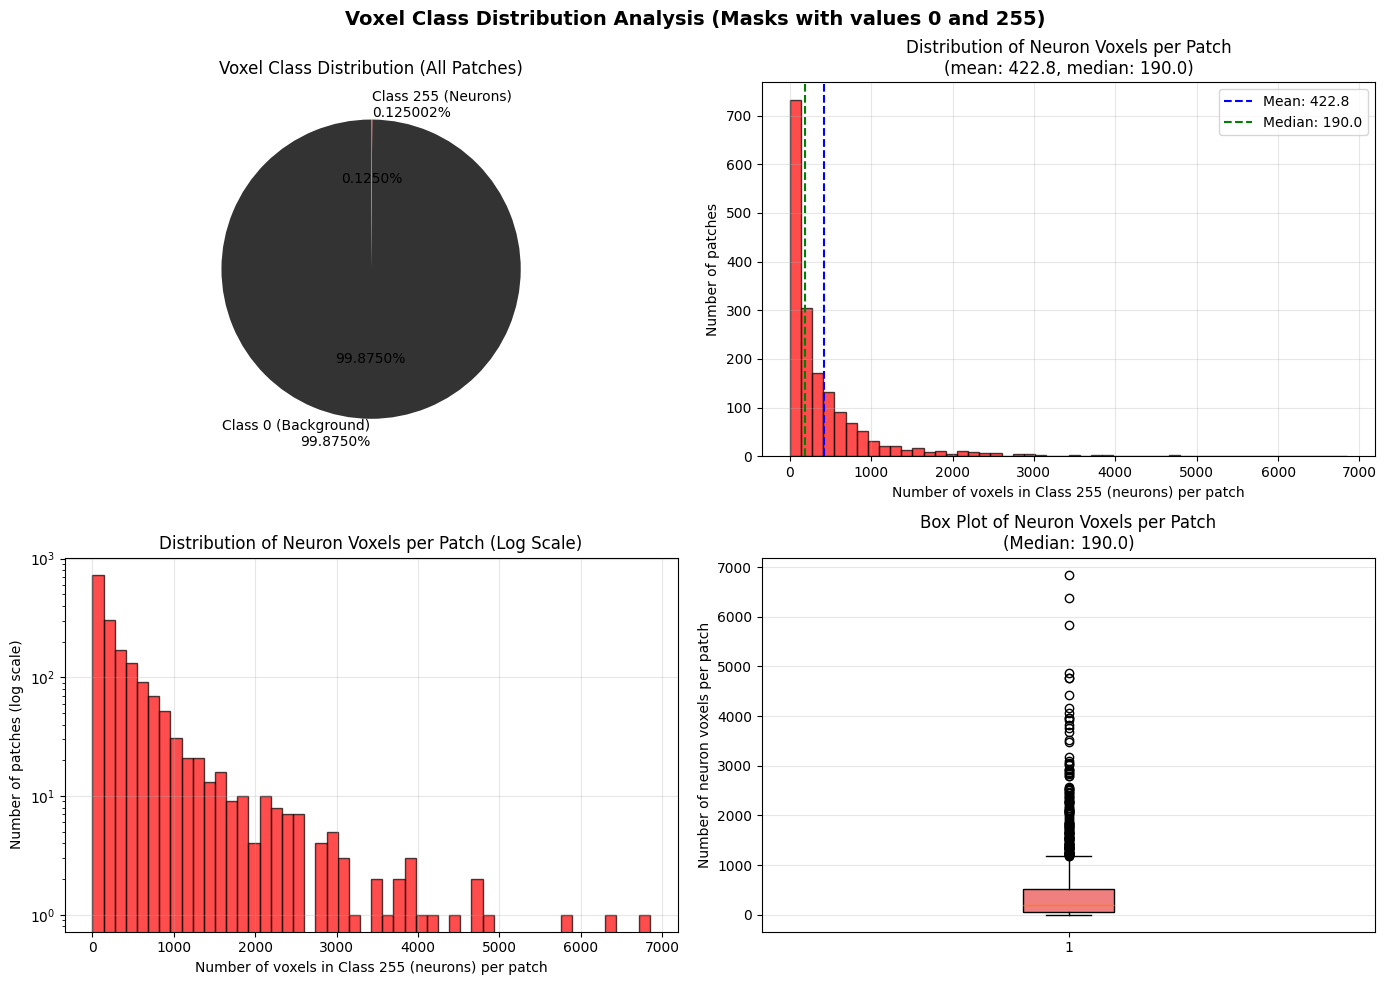

In [7]:
# Plot class distribution
plot_class_distribution(stats, save_path="../outputs/voxel_class_distribution.png")

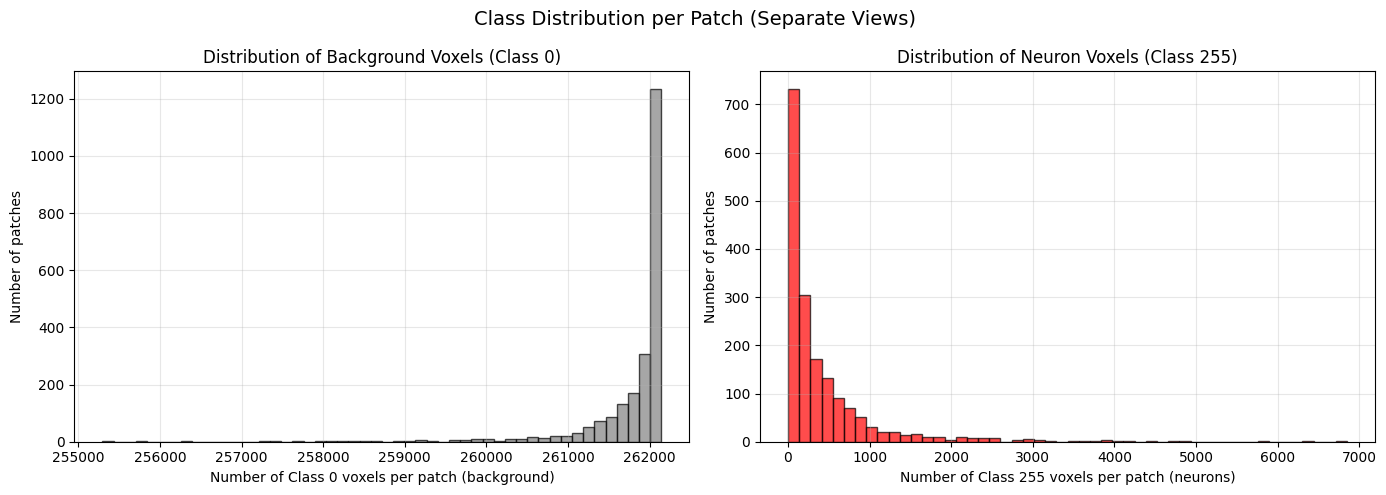

In [8]:
# Cell 7: Plot class distribution per patch (separate views)
plot_class_distribution_per_patch(stats)

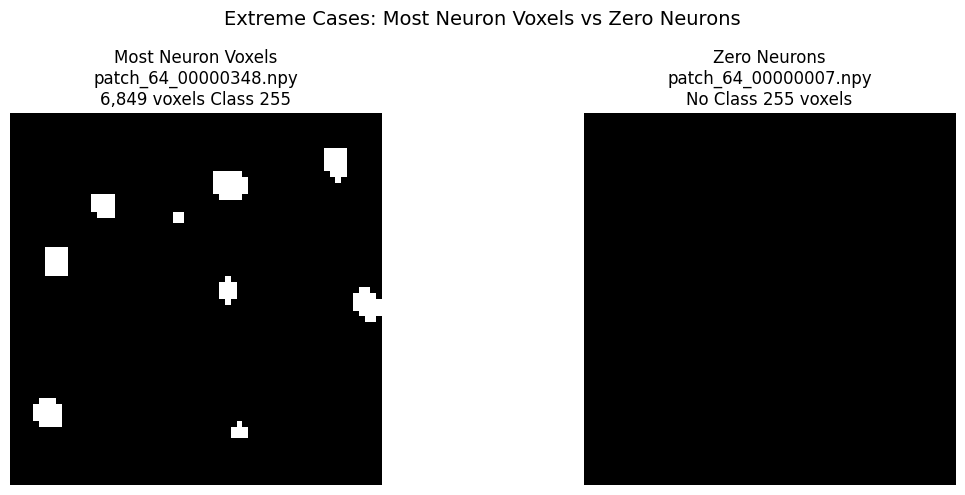

In [9]:
# Plot extreme masks
plot_extreme_masks(masks, filenames, extreme_info, num_display=4)

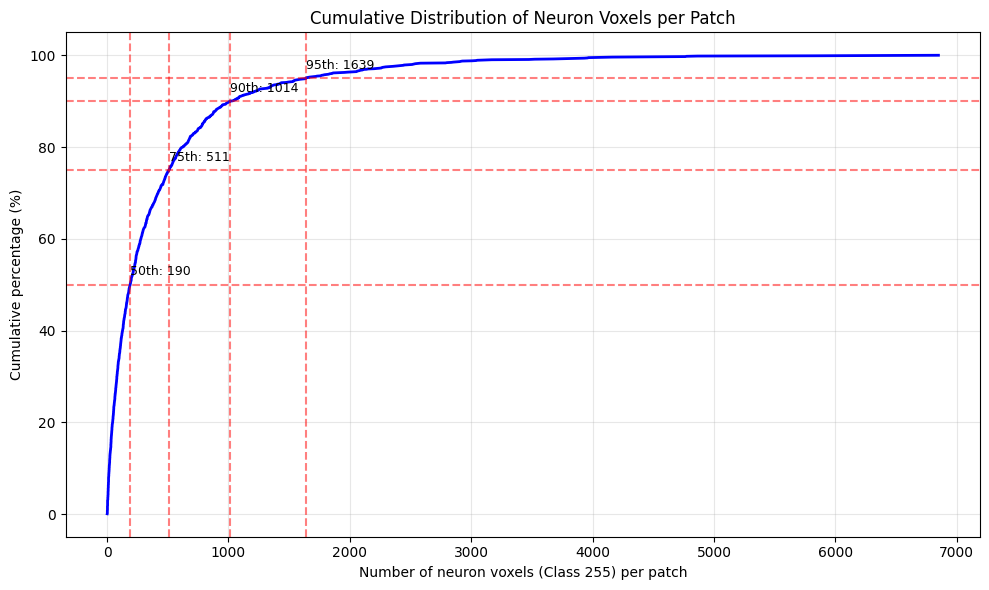

In [10]:
#  Cumulative distribution of neuron voxels per patch
class_255_nonzero = [c for c in stats['class_255_per_mask'] if c > 0]
if len(class_255_nonzero) > 0:
    sorted_voxels = np.sort(class_255_nonzero)
    cumulative = np.arange(1, len(sorted_voxels) + 1) / len(sorted_voxels) * 100
    
    plt.figure(figsize=(10, 6))
    plt.plot(sorted_voxels, cumulative, 'b-', linewidth=2)
    plt.xlabel('Number of neuron voxels (Class 255) per patch')
    plt.ylabel('Cumulative percentage (%)')
    plt.title('Cumulative Distribution of Neuron Voxels per Patch')
    plt.grid(True, alpha=0.3)
    
    # Add percentile lines
    for p in [50, 75, 90, 95]:
        perc_value = np.percentile(class_255_nonzero, p)
        plt.axhline(y=p, color='r', linestyle='--', alpha=0.5)
        plt.axvline(x=perc_value, color='r', linestyle='--', alpha=0.5)
        plt.text(perc_value, p + 2, f'{p}th: {perc_value:.0f}', fontsize=9)
    
    plt.tight_layout()
    plt.show()

In [11]:
#  Summary of findings
print("\n" + "=" * 70)
print("SUMMARY OF FINDINGS")
print("=" * 70)
print(f"Total patches analyzed: {stats['num_masks']}")
print(f"Total neuron voxels (Class 255): {stats['total_class_255']:,}")
print(f"Average neuron voxels per patch: {stats['total_class_255'] / stats['num_masks']:.2f}")
print(f"Class ratio (Class 0 / Class 255): 1 : {stats['class_ratio']:.2f}")
print()
print(f"Percentage of background voxels: {stats['class_0_percentage']:.4f}%")
print(f"Percentage of neuron voxels: {stats['class_255_percentage']:.6f}%")
print()

if stats['class_ratio'] > 10000:
    print("⚠️ EXTREME IMBALANCE: More than 10,000 background voxels per neuron voxel")
    print("   You MUST use Dice Loss or Tversky Loss")
    print("   Consider Focal Loss with gamma >= 3")
elif stats['class_ratio'] > 1000:
    print("⚠️ SEVERE IMBALANCE: More than 1,000 background voxels per neuron voxel")
    print("   Recommended: Dice Loss or Focal Loss (gamma=2)")
elif stats['class_ratio'] > 100:
    print("⚠️ STRONG IMBALANCE: More than 100 background voxels per neuron voxel")
    print("   Recommended: Dice Loss or Weighted CrossEntropy")
elif stats['class_ratio'] > 10:
    print("⚠️ MODERATE IMBALANCE: More than 10 background voxels per neuron voxel")
    print("   Recommended: Weighted CrossEntropy or Dice Loss")
else:
    print("✓ BALANCED: Less than 10 background voxels per neuron voxel")
    print("   Standard CrossEntropy may work")



SUMMARY OF FINDINGS
Total patches analyzed: 2244
Total neuron voxels (Class 255): 735,326
Average neuron voxels per patch: 327.69
Class ratio (Class 0 / Class 255): 1 : 798.99

Percentage of background voxels: 99.8750%
Percentage of neuron voxels: 0.125002%

⚠️ STRONG IMBALANCE: More than 100 background voxels per neuron voxel
   Recommended: Dice Loss or Weighted CrossEntropy


In [12]:
#  Save report
output_dir = Path("../outputs/reports")
output_dir.mkdir(parents=True, exist_ok=True)

report_path = output_dir / "voxel_class_distribution_report.txt"
generate_report(stats, output_path=report_path)

print(f"\nReport saved to: {report_path}")


VOXEL CLASS DISTRIBUTION ANALYSIS REPORT

Number of patches analyzed: 2244
Patches containing neurons: 1739
Patches without neurons (pure background): 505

Total voxels across all patches:
  Total voxels: 588,251,136
  Class 0 (background, bruit, artefacts): 587,515,810 (99.8750%)
  Class 255 (neurones): 735,326 (0.125002%)

Class ratio (Class 0 / Class 255): 1 : 798.99

Per patch statistics (voxels Class 255):
  Min voxels per patch: 0
  Max voxels per patch: 6,849
  Mean voxels per patch: 327.69
  Median voxels per patch: 105.00

RECOMMENDATION FOR LOSS FUNCTION:
  STRONG IMBALANCE: Use Dice Loss or Weighted CrossEntropy


Report saved to: ../outputs/reports/voxel_class_distribution_report.txt


In [13]:
#  Quick check - total neurons (objects) is different from neuron voxels
print("\n" + "=" * 70)
print("IMPORTANT NOTE")
print("=" * 70)
print(f"Total neuron voxels (Class 255): {stats['total_class_255']:,}")
print("This is NOT the number of neurons.")
print("Each neuron is a spherical object that can be hundreds of voxels.")
print(f"Example: If average neuron size is 500 voxels, estimated neurons ~ {stats['total_class_255'] / 500:.0f}")
print("The actual number of neurons will be calculated during evaluation.")



IMPORTANT NOTE
Total neuron voxels (Class 255): 735,326
This is NOT the number of neurons.
Each neuron is a spherical object that can be hundreds of voxels.
Example: If average neuron size is 500 voxels, estimated neurons ~ 1471
The actual number of neurons will be calculated during evaluation.
